In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "mc_multitask")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(
        f"  {param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [3]:
from src.models.mtf_model import MTFModel
from src.main import init_dataset
DEVICE = tc.device("cpu")
RUN = "001"

In [4]:
observations_test = []
externals_test = []
for measurement_folder in ['20230425', '20210715', '20230404', '20210405', '20220930', '20210412', '20230320', '20210624', '20200317', '20230405', '20230508', '20220221']:
    spikes = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/observations/1_spikes.pkl", allow_pickle=True)
    finger_position = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/observations/2_finger_position.pkl", allow_pickle=True)
    observations_test.append(tc.cat([tc.as_tensor(np.concatenate(spikes)), tc.as_tensor(np.concatenate(finger_position))], dim=-1).float())
    
    targets = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/externals/target_position.pkl", allow_pickle=True)
    externals_test.append(tc.as_tensor(np.concatenate(targets)).float())

params_ldim=94_dim_forcing=10_mks1=13_mks2=3_mks3=13_relu=29_feat=4_mar=3_enc_lr=0p00_dec_lr=0p03_dsr_lr=0p01_lr_gamma=1p00_gtf=0p01_gtf_gamma=0p88_aent=0p00_adsr=83p55_ac=0p04_ar=0p01_asc=0p01_alpha_mar=0p01
Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936


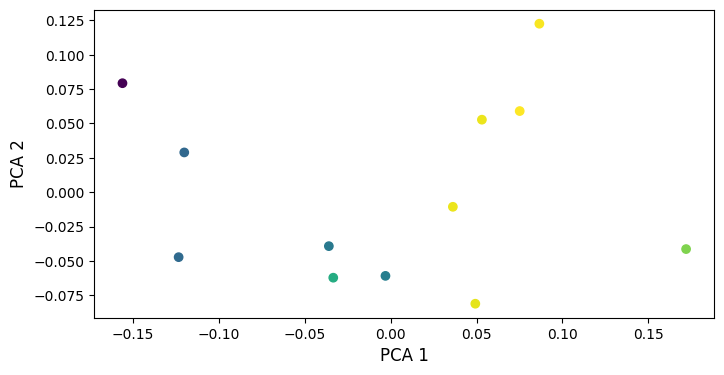

Average MSE = 0.8902 ± 1.7509, params_ldim=94_dim_forcing=10_mks1=13_mks2=3_mks3=13_relu=29_feat=4_mar=3_enc_lr=0p00_dec_lr=0p03_dsr_lr=0p01_lr_gamma=1p00_gtf=0p01_gtf_gamma=0p88_aent=0p00_adsr=83p55_ac=0p04_ar=0p01_asc=0p01_alpha_mar=0p01


In [7]:
import pandas as pd

days = []
for date in ['20230425', '20210715', '20230404', '20210405', '20220930', '20210412', '20230320', '20210624', '20200317', '20230405', '20230508', '20220221']:
    # extract date from filename which is the 6 digit number after "ses-"
    # format date from YYYYMMDD to YYYY-MM-DD
    date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
    # days since first date
    day = (pd.to_datetime(date) - pd.to_datetime("2020-01-27")).days
    days.append(day)
    
candidates = [subpath for subpath in os.listdir(RESULTS_PATH) if subpath.startswith("params_") and "001" in os.listdir(os.path.join(RESULTS_PATH, subpath))
              and "model_3000.pt" in os.listdir(os.path.join(RESULTS_PATH, subpath, RUN))]

for i, subpath in enumerate(candidates):
    print(subpath)
        
    # load model
    run_path = os.path.join(RESULTS_PATH, subpath, RUN)
    parameters = json.load(open(f"{run_path}/config.json"))
    dataset = init_dataset(parameters, DEVICE)
    model = MTFModel(dataset, model_path=run_path, device=DEVICE)
    MEASUREMENT_INDEX_TO_TS_INDEX = {dataset.evaluator_test_samples[i].measurement_index: dataset.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(dataset.evaluator_test_samples)-1, -1, -1)}

    test_mse = []
    for measurement_index in range(12):
        cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
        
        for time_series_index in range(len(observations_test[measurement_index]) // 200):
            latent_trajectory, encoded_trajectory, trajectory = model.generate_free_trajectory(
                observations_test[measurement_index][time_series_index*200:(time_series_index+1)*200],
                cumulative_timeseries_index,
                measurement_index,
                external_inputs=externals_test[measurement_index][time_series_index*200:(time_series_index+1)*200],
                use_expected_output=False,
            )[:3]
            

            # compute mse of last 4 dimensions
            mse = nn.MSELoss()(
                trajectory[:, :], observations_test[measurement_index][time_series_index*200:(time_series_index+1)*200]).item()
            
            test_mse.append(mse)
        
    pca = PCA(n_components=2)
    fig = plt.figure(figsize=(8, 4))
    subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
    subject_vectors_2d = pca.fit_transform(subject_vectors)
    plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=days, cmap="viridis", label="Subject Vectors")
    plt.ylabel("PCA 2", fontsize=FONT_SIZE)
    plt.xlabel("PCA 1", fontsize=FONT_SIZE)
    plt.show()
    print(f"Average MSE = {np.mean(test_mse):.4f} ± {np.std(test_mse):.4f},", subpath)

In [12]:
trial = get_trial_by_number(study.trials, 103)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)
trial_folder_name = "params_ldim=94_dim_forcing=10_mks1=13_mks2=3_mks3=13_relu=29_feat=4_mar=3_enc_lr=0p00_dec_lr=0p03_dsr_lr=0p01_lr_gamma=1p00_gtf=0p01_gtf_gamma=0p88_aent=0p00_adsr=83p55_ac=0p04_ar=0p01_asc=0p01_alpha_mar=0p01"

params_ldim=96_dim_forcing=10_mks1=15_mks2=3_mks3=11_relu=36_feat=4_mar=3_enc_lr=0p00_dec_lr=0p01_dsr_lr=0p01_lr_gamma=0p99_gtf=0p01_gtf_gamma=0p96_aent=0p00_adsr=35p69_ac=0p32_ar=0p04_asc=0p01_alpha_mar=0p00


In [13]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
tine_series_per_measurement = 5

parameters = json.load(open(f"{run_path}/config.json"))
dataset = init_dataset(parameters, DEVICE)
model = MTFModel(dataset, model_path=run_path, device=DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX = {dataset.evaluator_test_samples[i].measurement_index: dataset.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(dataset.evaluator_test_samples)-1, -1, -1)}


Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936


In [17]:
trajectories_train = []
trajectories_val = []
trajectories_test = []
latent_trajectories_test = []
encoded_trajectories_test = []

for time_series_index in range(len(dataset.evaluator_train_samples)):
    observations_train = dataset.evaluator_train_samples[time_series_index].input
    externals_train = dataset.evaluator_train_samples[time_series_index].external
    cumulative_timeseries_index = dataset.evaluator_train_samples[time_series_index].cumulative_timeseries_index
    measurement_index = dataset.evaluator_train_samples[time_series_index].measurement_index
    
    trajectory = model.generate_free_trajectory(
        observations_train,
        cumulative_timeseries_index,
        measurement_index,
        external_inputs=externals_train,
        use_expected_output=True,
    )[2].detach().cpu()
    trajectories_train.append(trajectory)

for time_series_index in range(len(dataset.evaluator_test_samples)):
    observations_val = dataset.evaluator_test_samples[time_series_index].input
    externals_val = dataset.evaluator_test_samples[time_series_index].external
    cumulative_timeseries_index = dataset.evaluator_test_samples[time_series_index].cumulative_timeseries_index
    measurement_index = dataset.evaluator_test_samples[time_series_index].measurement_index

    trajectory = model.generate_free_trajectory(
        observations_val,
        cumulative_timeseries_index,
        measurement_index,
        external_inputs=externals_val,
        use_expected_output=True,
    )[2].detach().cpu()
    trajectories_val.append(trajectory)


for measurement_index in range(12):
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
    trajectories_test_ = []
    latent_trajectories_test_ = []
    encoded_trajectories_test_ = []
    
    for time_series_index in range(len(observations_test[measurement_index]) // 200):
        latent_trajectory, encoded_trajectory, trajectory = model.generate_free_trajectory(
            observations_test[measurement_index][time_series_index*200:(time_series_index+1)*200],
            cumulative_timeseries_index,
            measurement_index,
            external_inputs=externals_test[measurement_index][time_series_index*200:(time_series_index+1)*200],
            use_expected_output=True,
        )[:3]

        trajectories_test_.append(trajectory.detach().cpu())
        latent_trajectories_test_.append(latent_trajectory.detach().cpu())
        encoded_trajectories_test_.append(encoded_trajectory.detach().cpu())
    
    trajectories_test.append(tc.cat(trajectories_test_, dim=0))
    latent_trajectories_test.append(tc.cat(latent_trajectories_test_, dim=0))
    encoded_trajectories_test.append(tc.cat(encoded_trajectories_test_, dim=0))

In [19]:
observations_test[0].shape

torch.Size([5200, 98])

In [21]:
train_mse = []
print("Train set results:")
for time_series_index in range(len(dataset.evaluator_train_samples)):
    trajectory = trajectories_train[time_series_index]
    observations_train = dataset.evaluator_train_samples[time_series_index].input

    # last 2 dims: behavioral variables (finger position), first 96 dims: neural variables (spikes)
    mse = nn.MSELoss()(trajectory[:, :], observations_train[:, :]).item()
    train_mse.append(mse)
    print(f"MSE = {mse:.4f},")
print(f"Average MSE = {np.mean(train_mse):.4f} ± {np.std(train_mse):.4f},")

print("\nValidation set results:")
for time_series_index in range(len(dataset.evaluator_test_samples)):
    trajectory = trajectories_val[time_series_index]
    observations_val = dataset.evaluator_test_samples[time_series_index].input

    # compute mse of last 4 dimensions
    mse = nn.MSELoss()(trajectory[:, :], observations_val[:, :]).item()
    print(f"MSE = {mse:.4f},")

print("\nTest set results:")
test_mse = []
for time_series_index in range(len(trajectories_test)):
    trajectory = trajectories_test[time_series_index][:observations_test[time_series_index].shape[0]]

    # compute mse of last 4 dimensions
    mse = nn.MSELoss()(
        trajectory[:, -2:], observations_test[time_series_index][:, -2:]).item()
    
    test_mse.append(mse)
print(f"Median MSE = {np.median(test_mse):.4f}")

Train set results:
MSE = 0.7004,
MSE = 0.6737,
MSE = 0.7760,
MSE = 0.7274,
MSE = 0.7157,
MSE = 0.6874,
MSE = 0.7335,
MSE = 0.7542,
MSE = 0.9728,
MSE = 0.6742,
MSE = 0.6577,
MSE = 0.7864,
MSE = 0.6084,
MSE = 1.0741,
MSE = 0.6069,
MSE = 0.6698,
MSE = 0.8982,
MSE = 0.7256,
MSE = 0.8737,
MSE = 0.6409,
MSE = 1.1434,
MSE = 0.7525,
MSE = 0.6548,
MSE = 0.7529,
MSE = 0.8674,
MSE = 0.7815,
MSE = 0.9931,
MSE = 0.7350,
MSE = 0.6740,
MSE = 1.1337,
MSE = 0.6117,
MSE = 0.6742,
MSE = 0.9661,
MSE = 0.8121,
MSE = 1.0130,
MSE = 0.9878,
MSE = 0.6329,
MSE = 0.8211,
MSE = 0.6699,
MSE = 0.7676,
MSE = 0.9530,
MSE = 0.6852,
MSE = 1.2311,
MSE = 1.2470,
MSE = 0.6202,
MSE = 0.7006,
MSE = 0.6661,
MSE = 0.7310,
MSE = 0.6534,
MSE = 0.6680,
MSE = 0.5982,
MSE = 0.7661,
MSE = 0.7199,
MSE = 0.7237,
MSE = 0.9022,
MSE = 1.6076,
MSE = 0.6985,
MSE = 0.8817,
MSE = 0.7640,
MSE = 0.8758,
Average MSE = 0.8016 ± 0.1882,

Validation set results:
MSE = 1.0619,
MSE = 1.0183,
MSE = 0.9186,
MSE = 0.7705,
MSE = 0.6113,
MSE = 1.1114,
M

array([0.6656236 , 0.30341008], dtype=float32)

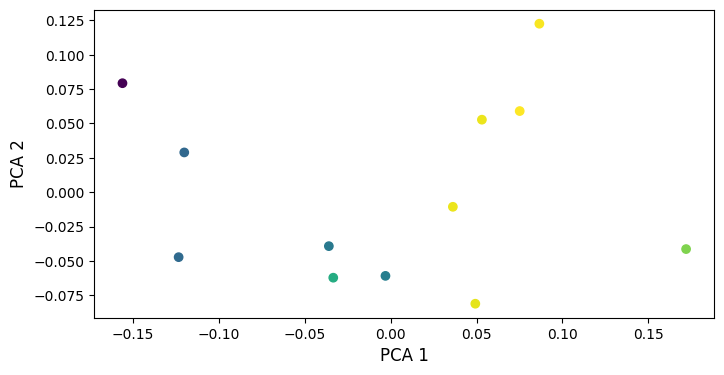

In [16]:
# plot pca subject vectors
import pandas as pd
from sklearn.decomposition import PCA
days = []
for date in ['20230425', '20210715', '20230404', '20210405', '20220930', '20210412', '20230320', '20210624', '20200317', '20230405', '20230508', '20220221']:
    # extract date from filename which is the 6 digit number after "ses-"
    # format date from YYYYMMDD to YYYY-MM-DD
    date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
    # days since first date
    day = (pd.to_datetime(date) - pd.to_datetime("2020-01-27")).days
    days.append(day)
    
colors = days
pca = PCA(n_components=2)
fig = plt.figure(figsize=(8, 4))
subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d = pca.fit_transform(subject_vectors)
plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=colors, cmap="viridis", label="Subject Vectors")
plt.ylabel("PCA 2", fontsize=FONT_SIZE)
plt.xlabel("PCA 1", fontsize=FONT_SIZE)
pca.explained_variance_ratio_